# Data Skew, Salting & Adaptive Query Execution

A shuffle sends all rows with the same key to the same task. If one key holds a large share of the rows, one task
gets much more work than the others. The stage ends only when its slowest task ends, so the other cores wait.
This is **data skew**. It is one of the most common reasons why a Spark job is slow even on a large cluster.

This lesson measures skew in real taxi data, shows its effect on the tasks of a join with the Spark REST API, and
compares three fixes: **salting**, the **AQE skew join** and a **broadcast join**.

**After this lesson you can:**

1. Measure key skew in a dataset and in the tasks of a shuffle stage (max vs median task).
2. Fix a skewed join with salting: a random salt on the large side, an exploded small side.
3. Configure Adaptive Query Execution (AQE) so that it splits skewed partitions, and find the split in the plan.
4. Choose between salting, AQE and a broadcast join.

**Data:** NYC taxi trips, January 2024 (2.96 million rows), and the taxi zone lookup table (265 zones).
**Services:** none (Spark runs locally in the notebook).

In [1]:
import shutil
import statistics
import sys
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
WORK = Path(tempfile.gettempdir()) / "fzth-m13" / "l07"
shutil.rmtree(WORK, ignore_errors=True); WORK.mkdir(parents=True)

PARTS = 32                                        # shuffle partitions for every join in this lesson
spark = (SparkSession.builder.master("local[4]").appName("m13-l07")
         .config("spark.driver.memory", "1500m").config("spark.sql.shuffle.partitions", str(PARTS))
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.autoBroadcastJoinThreshold", "-1")            # force a shuffle join (sort-merge)
         .config("spark.sql.adaptive.autoBroadcastJoinThreshold", "-1")   # AQE must not switch to broadcast either
         .config("spark.sql.adaptive.coalescePartitions.enabled", "false")  # keep 32 tasks, easy to compare
         .config("spark.sql.adaptive.skewJoin.enabled", "false")          # off for now; section 4 turns it on
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
API = f"{spark.sparkContext.uiWebUrl}/api/v1/applications/{spark.sparkContext.applicationId}"
print("Spark", spark.version, "| AQE:", spark.conf.get("spark.sql.adaptive.enabled"), "| REST API:", API)

trips = (spark.read.parquet(str(datasets.taxi("2024-01")))
         .select("PULocationID", "fare_amount", "tip_amount"))
zones = (spark.read.option("header", True).option("inferSchema", True).csv(str(datasets.fetch("taxi_zone_lookup.csv")))
         .select(F.col("LocationID").alias("PULocationID"), "Borough", "Zone"))
print(f"trips: {trips.count():,} | zones: {zones.count()}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/17 23:11:58 WARN Utils: Your hostname, Muhammet, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/17 23:11:58 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/17 23:11:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | AQE: true | REST API: http://10.255.255.254:4040/api/v1/applications/local-1794946320743


trips: 2,964,624 | zones: 265


## 1. Skew in Real Data

A key is skewed when a few values hold a large share of the rows. Pickup zones are a good example: Manhattan and
the airports (JFK is zone 132, LaGuardia is zone 138) are much busier than the outer zones.

A shuffle puts each key into a partition with `hash(key) mod 32`. One partition contains several keys, so the
partition sizes depend on the shares of the keys **and** on which keys share a partition. The cell measures both.

 PULocationID                      Zone  count  share_%
          132               JFK Airport 145240     4.90
          161            Midtown Center 143471     4.84
          237     Upper East Side South 142708     4.81
          236     Upper East Side North 136465     4.60
          162              Midtown East 106717     3.60
          230 Times Sq/Theatre District 106324     3.59
zones with trips: 260 | top 10 zones: 39.4 % of trips | bottom 130 zones: 0.45 %


rows per partition: max 321,448 | median 79,916 | max/median 4.0


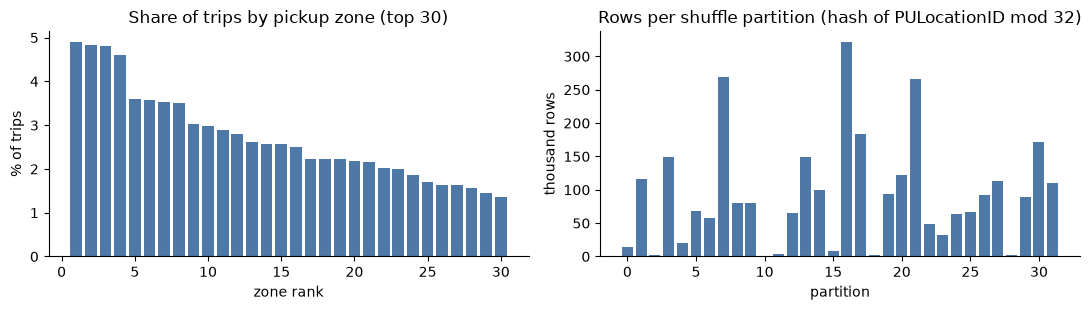

In [2]:
per_zone = (trips.groupBy("PULocationID").count().join(zones, "PULocationID", "left")
            .orderBy(F.desc("count")).toPandas())
per_zone["share_%"] = 100 * per_zone["count"] / per_zone["count"].sum()
print(per_zone.head(6)[["PULocationID", "Zone", "count", "share_%"]].round(2).to_string(index=False))
print(f"zones with trips: {len(per_zone)} | top 10 zones: {per_zone['share_%'].head(10).sum():.1f} % of trips | "
      f"bottom 130 zones: {per_zone['share_%'].tail(130).sum():.2f} %")

# rows per shuffle partition, with the same hash partitioning that a join on PULocationID uses
per_part = (trips.repartition(PARTS, "PULocationID").groupBy(F.spark_partition_id().alias("p")).count()
            .toPandas().set_index("p")["count"].reindex(range(PARTS), fill_value=0))
print(f"rows per partition: max {per_part.max():,} | median {int(per_part.median()):,} | "
      f"max/median {per_part.max() / per_part.median():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].bar(range(1, 31), per_zone["share_%"].head(30), color="#4E79A7")
ax[0].set(title="Share of trips by pickup zone (top 30)", xlabel="zone rank", ylabel="% of trips")
ax[1].bar(per_part.index, per_part.values / 1000, color="#4E79A7")
ax[1].set(title=f"Rows per shuffle partition (hash of PULocationID mod {PARTS})", xlabel="partition",
          ylabel="thousand rows")
plt.tight_layout(); plt.show()

*Insight: The real data is skewed, but moderately: the busiest zone holds about 5 % of the trips. The largest of
the 32 partitions is 4 times the median, because hash partitioning puts several busy zones into the same partition.*

## 2. A Strongly Skewed Join

Production skew is often much stronger: a default value such as `0` or `"unknown"`, one very large customer, or a
bot that sends millions of events. To create this on a laptop, the cell copies the JFK trips (zone 132) 10 times,
for example as if one airport feed delivered its data 10 times. Then zone 132 holds a third of all rows.

The join adds the borough name to each trip and the query sums fares per borough. The data is cached, so the
measurement shows the join stage and not the Parquet read.

In [3]:
JFK_COPIES = 10
hot = (trips.where("PULocationID = 132")                     # 9 extra copies of every JFK trip
       .withColumn("copy", F.explode(F.sequence(F.lit(2), F.lit(JFK_COPIES)))).drop("copy"))
skewed = trips.unionByName(hot).cache()
n_rows, n_hot = skewed.count(), skewed.where("PULocationID = 132").count()
print(f"skewed trips: {n_rows:,} rows | zone 132: {n_hot:,} rows = {100 * n_hot / n_rows:.1f} %")

def query(left, right, keys="PULocationID"):
    return (left.join(right, keys).groupBy("Borough")
            .agg(F.count("*").alias("trips"), F.round(F.sum("fare_amount"), 0).alias("fares")))

def stage_tasks(group: str) -> pd.DataFrame:
    """Tasks of the stage that reads the most shuffle records in this job group (= the join stage)."""
    for _ in range(50):                                        # the REST store is updated asynchronously
        jobs = [j for j in requests.get(f"{API}/jobs", timeout=10).json() if j.get("jobGroup") == group]
        if jobs and all(j["status"] == "SUCCEEDED" for j in jobs):
            break
        time.sleep(0.2)
    stages = [s for j in jobs for sid in j["stageIds"]
              for s in requests.get(f"{API}/stages/{sid}", timeout=10).json() if s["status"] == "COMPLETE"]
    s = max(stages, key=lambda s: s["shuffleReadRecords"])
    tasks = requests.get(f"{API}/stages/{s['stageId']}/{s['attemptId']}/taskList?length=10000", timeout=10).json()
    return pd.DataFrame({"records": [t["taskMetrics"]["shuffleReadMetrics"]["recordsRead"] for t in tasks],
                         "ms": [t["taskMetrics"]["executorRunTime"] for t in tasks],
                         "mb": [(t["taskMetrics"]["shuffleReadMetrics"]["localBytesRead"] +
                                 t["taskMetrics"]["shuffleReadMetrics"]["remoteBytesRead"]) / 2**20 for t in tasks]})

def measure(name: str, make_df, runs: int = 3):
    """Best wall time of `runs` fresh queries + the task statistics of the join stage of the best run.

    A fresh DataFrame per run: re-running the same DataFrame would reuse its finished shuffle stages."""
    best = None
    for r in range(runs):
        group = f"{name}-{r}"
        spark.sparkContext.setJobGroup(group, group)
        df = make_df()
        t0 = time.perf_counter(); result = df.collect(); sec = time.perf_counter() - t0
        if best is None or sec < best[0]:
            best = (sec, group, result, df)
    spark.sparkContext.setJobGroup("other", "other")
    tasks = stage_tasks(best[1])
    row = {"variant": name, "seconds": round(best[0], 2), "join tasks": len(tasks),
           "max records": int(tasks.records.max()), "median records": int(tasks.records.median()),
           "max task ms": int(tasks.ms.max()), "median task ms": int(tasks.ms.median())}
    return row, tasks, sorted(best[2]), best[3]

r_base, t_base, res_base, _ = measure("1 baseline (sort-merge)", lambda: query(skewed, zones))
print(pd.DataFrame([r_base]).to_string(index=False))
print("result:", [(r.Borough, r.trips) for r in res_base][:4], "...")

skewed trips: 4,271,784 rows | zone 132: 1,452,400 rows = 34.0 %


                variant  seconds  join tasks  max records  median records  max task ms  median task ms
1 baseline (sort-merge)     1.45          32      1573502           79925          603              51
result: [('Bronx', 6905), ('Brooklyn', 25258), ('EWR', 295), ('Manhattan', 2646948)] ...


The REST API (`/applications/<id>/stages/<id>/<attempt>/taskList`) returns the metrics of every task:
`recordsRead` is the number of shuffle rows the task received, `executorRunTime` the time it ran.

In [4]:
t_sorted = t_base.sort_values("records", ascending=False).reset_index(drop=True)
print(f"largest task: {t_sorted.records[0]:,} records, {t_sorted.ms[0]} ms | "
      f"2nd largest: {t_sorted.records[1]:,} records | median: {int(t_base.records.median()):,} records, "
      f"{int(t_base.ms.median())} ms")
print(f"the largest task reads {100 * t_sorted.records[0] / t_base.records.sum():.0f} % of all shuffle records; "
      f"max/median records = {t_sorted.records[0] / t_base.records.median():.0f}x")

largest task: 1,573,502 records, 603 ms | 2nd largest: 321,455 records | median: 79,925 records, 51 ms
the largest task reads 37 % of all shuffle records; max/median records = 20x


*Insight: One of the 32 join tasks receives 37 % of all shuffle rows (1.57 million), 20 times the median task, and
it runs about 12 times longer than the median task (603 ms against 51 ms). While it runs, the other cores have nothing to do. In local mode with
4 cores the cost is small in seconds; on a cluster with hundreds of cores the whole job waits for one task.*

## 3. Fix 1: Salting

**Salting** splits the hot key into many keys by hand:

1. The large side gets a random column `salt` in `0 .. N-1`, so the rows of zone 132 spread over `N` keys
   `(132, 0) ... (132, N-1)`.
2. The small side is **exploded**: every zone row is copied `N` times, once for each salt value.
3. The join uses `(PULocationID, salt)`. Every trip still finds its zone exactly once.

The cost: the small side becomes `N` times larger, and the code must change. With `N = 16` the zone table grows from
265 to 4,240 rows.

In [5]:
N_SALT = 16
salted_left = skewed.withColumn("salt", (F.rand(seed=7) * N_SALT).cast("int"))
salted_right = zones.crossJoin(spark.range(N_SALT).withColumnRenamed("id", "salt"))
print("small side rows after explode:", salted_right.count())

r_salt, t_salt, res_salt, _ = measure("2 salting (N=16)",
                                      lambda: query(salted_left, salted_right, ["PULocationID", "salt"]))
print(pd.DataFrame([r_base, r_salt]).to_string(index=False))
print("same result as the baseline:", res_salt == res_base)

small side rows after explode: 4240


                variant  seconds  join tasks  max records  median records  max task ms  median task ms
1 baseline (sort-merge)     1.45          32      1573502           79925          603              51
       2 salting (N=16)     1.44          32       264655          108800          205              97
same result as the baseline: True


*Insight: With 16 salts the largest join task drops from 1.57 million to about 265 thousand records (6 times
smaller), and the result is identical: each trip matches exactly one copy of its zone. The query is not faster on
4 cores, because the salt column and the 16 times larger zone table add work to every task (the median task grows
from about 80 to 109 thousand records). Salting pays off when the skewed task, not the total work, sets the time.*

## 4. Fix 2: AQE Skew Join

**Adaptive Query Execution** (AQE, on by default since Spark 3.2) re-optimizes the plan at the stage boundaries,
when the real sizes of the shuffle outputs are known. Its skew join rule splits a large shuffle partition into
several tasks and copies the matching partition of the other side to each of them. No code change is necessary.

A partition counts as skewed when **both** conditions hold:

| setting | default | here | meaning |
| :--- | :--- | :--- | :--- |
| `spark.sql.adaptive.skewJoin.skewedPartitionFactor` | 5 | 3 | partition size > factor x median size |
| `spark.sql.adaptive.skewJoin.skewedPartitionThresholdInBytes` | 256 MB | 1 MB | partition size > threshold |
| `spark.sql.adaptive.advisoryPartitionSizeInBytes` | 64 MB | 256 KB | target size of each split |

The defaults suit cluster data volumes. The shuffle in this lesson is only about 21 MB (Spark compresses shuffle blocks), so the
second cell lowers the thresholds. The first cell reads the real partition sizes of the baseline join stage from the REST API.

In [6]:
mb = t_base.mb
print(f"shuffle read per join task: max {mb.max():.1f} MB | median {mb.median():.2f} MB | total {mb.sum():.0f} MB | "
      f"max/median {mb.max() / mb.median():.0f}x")

shuffle read per join task: max 2.9 MB | median 0.51 MB | total 21 MB | max/median 6x


In [7]:
spark.conf.set("spark.sql.adaptive.skewJoin.enabled", "true")
spark.conf.set("spark.sql.adaptive.skewJoin.skewedPartitionFactor", "3")
spark.conf.set("spark.sql.adaptive.skewJoin.skewedPartitionThresholdInBytes", "1MB")
spark.conf.set("spark.sql.adaptive.advisoryPartitionSizeInBytes", "256KB")

r_aqe, t_aqe, res_aqe, aqe = measure("3 AQE skew join", lambda: query(skewed, zones))
print(pd.DataFrame([r_base, r_salt, r_aqe]).to_string(index=False))
print("same result as the baseline:", res_aqe == res_base)

plan = aqe._jdf.queryExecution().executedPlan().toString()       # the final plan after the run
print("isFinalPlan=true:", "isFinalPlan=true" in plan)
print([l.strip() for l in plan.splitlines() if "SortMergeJoin" in l or "AQEShuffleRead" in l])

                variant  seconds  join tasks  max records  median records  max task ms  median task ms
1 baseline (sort-merge)     1.45          32      1573502           79925          603              51
       2 salting (N=16)     1.44          32       264655          108800          205              97
        3 AQE skew join     1.01          41       558805           91832          249              43
same result as the baseline: True
isFinalPlan=true: True
['+- *(5) SortMergeJoin(skew=true) [PULocationID#7], [PULocationID#41], Inner', ':  +- AQEShuffleRead skewed', '+- AQEShuffleRead', '+- SortMergeJoin [PULocationID#7], [PULocationID#41], Inner']


`AQEShuffleRead skewed` and `SortMergeJoin(skew=true)` in the final plan show that the rule fired. The join stage
has 41 tasks instead of 32: the skewed partition was split into several tasks. The largest task still reads about
560 thousand records, because AQE splits a partition only between the outputs of map tasks: a piece cannot be
smaller than the block that one map task wrote for that partition.

*Insight: AQE cut the largest task to about a third, with three configuration lines and no code change, and it was
the fastest shuffle join in this run. It reacts to the real sizes at run time, so it also handles skew that was not
known when the code was written.*

## 5. Fix 3: Broadcast the Small Side

The zone table has 265 rows. If the small side fits in memory, the best fix is no shuffle of the large side at all:
a **broadcast hash join** sends a copy of the small table to every task, and each task joins its own part of the
large table locally. Hot keys do not matter, because the rows of zone 132 stay where they are.

In [8]:
spark.conf.set("spark.sql.adaptive.skewJoin.enabled", "false")
r_bc, t_bc, res_bc, bcast = measure("4 broadcast join", lambda: query(skewed, F.broadcast(zones)))
print("same result as the baseline:", res_bc == res_base)
plan = bcast._jdf.queryExecution().executedPlan().toString()
print([l.strip()[:60] for l in plan.splitlines() if "BroadcastHashJoin" in l or "SortMergeJoin" in l])

summary = pd.DataFrame([r_base, r_salt, r_aqe, r_bc])
print(summary.to_string(index=False))

same result as the baseline: True
['+- *(2) BroadcastHashJoin [PULocationID#7], [PULocationID#41', '+- BroadcastHashJoin [PULocationID#7], [PULocationID#41], In']
                variant  seconds  join tasks  max records  median records  max task ms  median task ms
1 baseline (sort-merge)     1.45          32      1573502           79925          603              51
       2 salting (N=16)     1.44          32       264655          108800          205              97
        3 AQE skew join     1.01          41       558805           91832          249              43
       4 broadcast join     0.40          32            6               0            2               1


For the broadcast join, the "join stage" in the table is the final aggregation stage, because the join itself
needs no shuffle: there is no skewed shuffle partition. The chart shows the records of every join task for the
three shuffle joins.

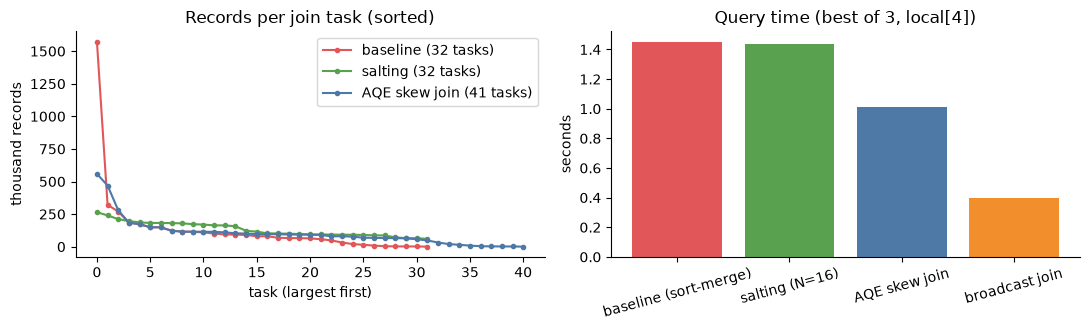

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for name, t, c in [("baseline", t_base, "#E15759"), ("salting", t_salt, "#59A14F"), ("AQE skew join", t_aqe, "#4E79A7")]:
    v = t.records.sort_values(ascending=False).reset_index(drop=True) / 1000
    ax[0].plot(v.index, v.values, marker="o", ms=3, label=f"{name} ({len(t)} tasks)", color=c)
ax[0].set(title="Records per join task (sorted)", xlabel="task (largest first)", ylabel="thousand records")
ax[0].legend()
ax[1].bar(summary.variant.str.slice(2), summary.seconds, color=["#E15759", "#59A14F", "#4E79A7", "#F28E2B"])
ax[1].set(title="Query time (best of 3, local[4])", ylabel="seconds")
ax[1].tick_params(axis="x", labelrotation=15)
plt.tight_layout(); plt.show()

*Insight: All three fixes shrink or remove the giant task. The broadcast join is the fastest here because it skips the
shuffle of 4.3 million rows; salting and AQE still shuffle the large side but spread the hot key over many tasks.
Local-mode timings are indicative only: with 4 cores, a long task blocks one core of four; on a cluster the gap grows
with the number of cores.*

| fix | when to use | cost |
| :--- | :--- | :--- |
| broadcast join | small side fits in executor memory (default auto limit 10 MB, often raised to a few hundred MB) | a copy of the small side per executor |
| AQE skew join | both sides large; sort-merge join; skew known only at run time | tune thresholds to your data size; sort-merge joins only |
| salting | AQE cannot help (e.g. skewed `groupBy`, old Spark, very extreme keys) | code change; the small side grows N times |

For a skewed **aggregation** (`groupBy` on a hot key), Spark already pre-aggregates on the map side, so the shuffle
moves one row per key per task. Skew there hurts mostly with `collect_list` or distinct counts; salting in two steps
(aggregate by `(key, salt)`, then by `key`) is the classic fix.

## Real-World Use Case or Analogy

A supermarket opens 32 checkouts and sends customers to a checkout by the first letter of their family name. If half
of the town has the same family name, one queue is very long while the other cashiers wait. Salting is "also use the
last digit of the birthday"; AQE is a manager who sees the long queue and opens extra checkouts for it; a broadcast
join is self-checkout: every customer pays where they stand.

Companies meet skew in event data (one large customer, one popular product, null user IDs for anonymous visitors)
and in joins of fact tables with dimension tables. The usual order of action: filter or handle null and default
keys first, broadcast small dimension tables, keep AQE on with thresholds that suit the data size, and use salting
for the remaining extreme cases.

In [10]:
skewed.unpersist()
spark.stop()